# Aim 2 feasibility on Tahoe-100M: is the well effect shared across cell lines?

Same question as the Parse notebook, in a second dataset. Each Tahoe well holds about 50 pooled cancer cell lines, so cell lines play the role of cell types.

**Data:** per-plate h5ad files downloaded by `aim2_download.ipynb` (section 4), plus the inferred well map (`tahoe_sample_wells_inferred.csv`).

**Tests**

| Test | Wells used | Question |
|---|---|---|
| A | 2 DMSO wells per plate (H11, H12 on plates 6 and 14; B11, B12 on plate 13, from the bc1 barcode) | DMSO-vs-DMSO pseudo-response: same well pair vs different plates, correlated across cell lines? |
| R | Replicate plates 6 and 14, all 96 wells | Same drug and dose in the same well of both plates, so `plate6 - plate14` holds no biology. Do residuals of the same well correlate across cell lines? |
| D | Same as R | How much of one cell line's well effect can be predicted from the **other** cell lines in the same well? Also only from cell lines of **other organs**. |

Tahoe has no inert drugs list, which is why Tests R and D use the replicate plates instead: the drug is the same on both plates, so drug biology cancels.

All outputs go to `results/cache/aim2_tahoe_shared_well_effect/`.

In [1]:
import os, time
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
from scipy.stats import rankdata
import matplotlib.pyplot as plt

TAHOE_H5AD_DIR = "data/tahoe100m_h5ad"
WELL_MAP = "results/cache/aim2_download/tahoe_sample_wells_inferred.csv"
CELL_LINE_META = "data/tahoe100m_metadata/metadata/cell_line_metadata.parquet"
OUT_DIR = "results/cache/aim2_tahoe_shared_well_effect"

PLATES = ["plate6", "plate14", "plate13"]   # plates 6 and 14 are replicates
REPLICATE = ("plate6", "plate14")
CHUNK = 200_000
MIN_CELLS = 30         # minimum cells per (plate, well, cell line) pseudobulk
N_GENES = 2000
N_LINE_PAIRS = 400     # random cell-line pairs used for the correlation tests
SEED = 0

os.makedirs(OUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
wells = pd.read_csv(WELL_MAP)
print(wells.groupby("plate").well_confident.first().to_dict())

{'plate1': True, 'plate10': True, 'plate11': True, 'plate12': True, 'plate13': False, 'plate14': True, 'plate2': True, 'plate3': True, 'plate4': True, 'plate5': True, 'plate6': True, 'plate7': True, 'plate8': True, 'plate9': True}


## 1. Look at one plate file

Checks the obs columns and whether `X` holds raw counts. Edit `LINE_COL` if the cell-line column has another name.

In [2]:
def plate_file(plate):
    f = [x for x in os.listdir(TAHOE_H5AD_DIR) if x.startswith(plate + "_") and x.endswith(".h5ad")]
    assert len(f) == 1, f"{plate}: found {f}"
    return os.path.join(TAHOE_H5AD_DIR, f[0])


a = ad.read_h5ad(plate_file(PLATES[0]), backed="r")
print(a)
print("obs columns:", a.obs.columns.tolist())
x = a.X[:2000]
x = x.toarray() if sp.issparse(x) else np.asarray(x)
print("X looks like raw counts:", bool(np.allclose(x, np.round(x))), "| max:", x.max())
LINE_COL = "cell_name" if "cell_name" in a.obs.columns else "cell_line"
print("Cell-line column:", LINE_COL, "|", a.obs[LINE_COL].nunique(), "cell lines")
print("Samples in this plate:", a.obs["sample"].nunique())
a.file.close()

AnnData object with n_obs × n_vars = 7545393 × 62710 backed at 'data/tahoe100m_h5ad/plate6_filt_Vevo_Tahoe100M_WServicesFrom_ParseGigalab.h5ad'
    obs: 'sample', 'gene_count', 'tscp_count', 'mread_count', 'drugname_drugconc', 'drug', 'cell_line', 'sublibrary', 'BARCODE', 'pcnt_mito', 'S_score', 'G2M_score', 'phase', 'pass_filter', 'cell_name', 'plate'
    layers: None (.X)
obs columns: ['sample', 'gene_count', 'tscp_count', 'mread_count', 'drugname_drugconc', 'drug', 'cell_line', 'sublibrary', 'BARCODE', 'pcnt_mito', 'S_score', 'G2M_score', 'phase', 'pass_filter', 'cell_name', 'plate']
X looks like raw counts: True | max: 1631.0
Cell-line column: cell_name | 50 cell lines
Samples in this plate: 96


### 1b. True well positions from the round-1 barcode
The BARCODE column holds the split-pool barcodes. The round-1 token is the one that has a single value per sample, and it gives the well (1-96, row-major: 1 = A1, 96 = H12). The result agrees 100% with the inferred well map on all three plates, including DMSO in B11/B12 on plate 13 (H11/H12 on plates 6 and 14). Caveat: bc1 gives the position on the round-1 barcoding plate; we assume it matches the drug plate layout.

In [3]:
def pos_to_well(p):
    p = int(p)
    return "ABCDEFGH"[(p - 1) // 12] + str((p - 1) % 12 + 1)

def barcode_well_map(plate):
    t0 = time.time()
    a = ad.read_h5ad(plate_file(plate), backed="r")
    obs = a.obs[["sample", "BARCODE", "drug"]].copy()
    a.file.close()
    obs["sample"] = obs["sample"].astype(str)
    print(f"{plate}: example barcodes {obs.BARCODE.astype(str).iloc[:3].tolist()}")

    # split "aa_bb_cc__s1" into tokens, drop the sublibrary suffix
    core = obs.BARCODE.astype(str).str.split("__").str[0]
    toks = core.str.split("_", expand=True)

    # the round-1 token: exactly one value per sample and ~96 values per plate
    best = None
    for j in toks.columns:
        purity = toks[j].groupby(obs["sample"].values).nunique()
        n_vals = toks[j].nunique()
        print(f"  token {j}: max values per sample = {purity.max()}, values per plate = {n_vals}")
        if purity.max() == 1 and 90 <= n_vals <= 96:
            best = j
    assert best is not None, "No barcode token is constant within samples; inspect BARCODE format."

    m = (pd.DataFrame({"sample": obs["sample"].values, "tok": toks[best].values,
                       "drug": obs["drug"].astype(str).values})
           .drop_duplicates(["sample", "tok"]))
    tok = m["tok"]
    if tok.str.fullmatch(r"\d+").all():                 # numeric well index
        m["pos"] = tok.astype(int)
        if m["pos"].min() == 0:
            m["pos"] += 1
    else:                                               # already a well name like A1
        r = tok.str[0].map({c: i for i, c in enumerate("ABCDEFGH")})
        m["pos"] = r * 12 + tok.str[1:].astype(int)
    m["well"] = m["pos"].map(pos_to_well)
    m["row"] = m["well"].str[0]
    m["col"] = m["well"].str[1:].astype(int)
    m["plate"] = plate
    m["well_confident"] = True

    dmso = m.loc[m.drug == "DMSO_TF", "well"].tolist()
    print(f"  DMSO wells: {sorted(dmso)} | {time.time() - t0:.0f}s")
    return m.drop(columns=["tok", "drug"])

bc_maps = pd.concat([barcode_well_map(p) for p in PLATES], ignore_index=True)

# compare with the inferred map (expect agreement on 6 and 14, disagreement on 13)
inf = pd.read_csv(WELL_MAP)
inf["sample"] = inf["sample"].astype(str)
cmp = bc_maps.merge(inf[["plate", "sample", "well"]], on=["plate", "sample"],
                    suffixes=("_barcode", "_inferred"))
print("\nAgreement with inferred map per plate:")
print(cmp.assign(agree=cmp.well_barcode == cmp.well_inferred)
         .groupby("plate").agree.mean().round(3).to_dict())

# write a barcode-based map with the same columns as the inferred one, and use it from here on
keep_cols = [c for c in inf.columns if c in bc_maps.columns]
missing = [c for c in inf.columns if c not in bc_maps.columns]
if missing:
    print("Columns carried over from the inferred map:", missing)
out = bc_maps[keep_cols].merge(inf[["plate", "sample"] + missing], on=["plate", "sample"], how="left") \
      if missing else bc_maps[keep_cols]
WELL_MAP = os.path.join(OUT_DIR, "tahoe_sample_wells_barcode.csv")
out.to_csv(WELL_MAP, index=False)
wells = out
print("Saved:", WELL_MAP, "|", out.shape)

plate6: example barcodes ['01_001_016', '01_001_039', '01_001_052']
  token 0: max values per sample = 1, values per plate = 96
  token 1: max values per sample = 192, values per plate = 192
  token 2: max values per sample = 192, values per plate = 192
  DMSO wells: ['H11', 'H12'] | 22s
plate14: example barcodes ['01_001_053', '01_001_141', '01_002_014']
  token 0: max values per sample = 1, values per plate = 96
  token 1: max values per sample = 192, values per plate = 192
  token 2: max values per sample = 192, values per plate = 192
  DMSO wells: ['H11', 'H12'] | 19s
plate13: example barcodes ['01_001_052', '01_001_062', '01_002_085']
  token 0: max values per sample = 1, values per plate = 96
  token 1: max values per sample = 192, values per plate = 192
  token 2: max values per sample = 192, values per plate = 192
  DMSO wells: ['B11', 'B12'] | 25s

Agreement with inferred map per plate:
{'plate13': 1.0, 'plate14': 1.0, 'plate6': 1.0}
Columns carried over from the inferred map:

In [5]:
import os, glob
import pandas as pd
import anndata as ad

TAHOE_H5AD_DIR = "data/tahoe100m_h5ad"
f = [x for x in os.listdir(TAHOE_H5AD_DIR) if x.startswith("plate13_") and x.endswith(".h5ad")][0]

a = ad.read_h5ad(os.path.join(TAHOE_H5AD_DIR, f), backed="r")
o = a.obs[["sample", "drug", "BARCODE"]].astype(str)
a.file.close()
o["bc1"] = o.BARCODE.str.split("_").str[0]
print("Plate 13 DMSO samples -> bc1 position:")
print(o[o.drug == "DMSO_TF"].groupby("sample").bc1.unique())

# what Aim 1 recorded for plate 13
hits = glob.glob("../Proposal2/**/tahoe_dmso_meta.csv", recursive=True)
print("\nAim 1 meta file:", hits)
if hits:
    old = pd.read_csv(hits[0])
    print(old.columns.tolist())
    pcol = [c for c in old.columns if "plate" in c.lower()][0]
    print(old[old[pcol].astype(str).str.contains("13")].drop_duplicates().head(10))

Plate 13 DMSO samples -> bc1 position:
sample
smp_2669    [23]
smp_2670    [24]
Name: bc1, dtype: object

Aim 1 meta file: ['../Proposal2/cache/tahoe_dmso_meta.csv']
['plate', 'sample', 'cell_line', 'half', 'n_cells']
       plate    sample  cell_line half  n_cells
800  plate13  smp_2669  CVCL_0023    A      738
801  plate13  smp_2669  CVCL_0023    B      770
802  plate13  smp_2669  CVCL_0028    A      197
803  plate13  smp_2669  CVCL_0028    B      191
804  plate13  smp_2669  CVCL_0069    A      661
805  plate13  smp_2669  CVCL_0069    B      672
806  plate13  smp_2669  CVCL_0099    A      685
807  plate13  smp_2669  CVCL_0099    B      646
808  plate13  smp_2669  CVCL_0131    A      576
809  plate13  smp_2669  CVCL_0131    B      578


## 2. Pseudobulk counts per (plate, sample, cell line)

One cached file per plate. About 10 to 20 minutes per plate the first time.

In [4]:
def pseudobulk_plate(plate):
    path = os.path.join(OUT_DIR, f"pseudobulk_{plate}.h5ad")
    if os.path.exists(path):
        print(f"{plate}: loaded cache")
        return ad.read_h5ad(path)
    a = ad.read_h5ad(plate_file(plate), backed="r")
    o = a.obs[["sample", LINE_COL]].astype(str)
    if "pass_filter" in a.obs.columns:
        keep = a.obs["pass_filter"].astype(str).isin(["full", "True", "true", "1"])
        if keep.mean() > 0.2:
            o.loc[~keep.values, "sample"] = np.nan
            print(f"{plate}: keeping pass_filter cells ({keep.mean():.0%})")
    key = (o["sample"] + "|" + o[LINE_COL]).where(o["sample"].notna())
    codes, groups = pd.factorize(key)
    acc = np.zeros((len(groups), a.n_vars), dtype=np.float32)
    t0 = time.time()
    for s in range(0, a.n_obs, CHUNK):
        e = min(s + CHUNK, a.n_obs)
        c = codes[s:e]
        m = c >= 0
        if m.any():
            X = a.X[s:e]
            X = X if sp.issparse(X) else sp.csr_matrix(X)
            X = X[np.where(m)[0]]
            ug, local = np.unique(c[m], return_inverse=True)
            G = sp.csr_matrix((np.ones(len(local), dtype=np.float32), (local, np.arange(len(local)))),
                              shape=(len(ug), len(local)))
            acc[ug] += np.asarray((G @ X).todense(), dtype=np.float32)
        el = time.time() - t0
        print(f"  {plate}: {e:,} / {a.n_obs:,} cells ({e / a.n_obs:.0%}) | elapsed {el / 60:.1f} min | "
              f"remaining ~{el / e * (a.n_obs - e) / 60:.0f} min", flush=True)
    meta = pd.DataFrame([g.split("|") for g in groups], columns=["sample", "line"])
    meta["n_cells"] = np.bincount(codes[codes >= 0], minlength=len(groups))
    meta["plate"] = plate
    meta.index = [f"{plate}_{i}" for i in range(len(groups))]
    pb = ad.AnnData(X=sp.csr_matrix(acc), obs=meta, var=pd.DataFrame(index=a.var_names.astype(str)))
    a.file.close()
    pb.write_h5ad(path)
    print(f"{plate}: saved {pb.shape} | {(time.time() - t0) / 60:.1f} min")
    return pb


PB = {p: pseudobulk_plate(p) for p in PLATES}

plate6: keeping pass_filter cells (97%)
  plate6: 200,000 / 7,545,393 cells (3%) | elapsed 0.2 min | remaining ~6 min
  plate6: 400,000 / 7,545,393 cells (5%) | elapsed 0.3 min | remaining ~6 min
  plate6: 600,000 / 7,545,393 cells (8%) | elapsed 0.5 min | remaining ~5 min
  plate6: 800,000 / 7,545,393 cells (11%) | elapsed 0.6 min | remaining ~5 min
  plate6: 1,000,000 / 7,545,393 cells (13%) | elapsed 0.8 min | remaining ~5 min
  plate6: 1,200,000 / 7,545,393 cells (16%) | elapsed 0.9 min | remaining ~5 min
  plate6: 1,400,000 / 7,545,393 cells (19%) | elapsed 1.1 min | remaining ~5 min
  plate6: 1,600,000 / 7,545,393 cells (21%) | elapsed 1.2 min | remaining ~5 min
  plate6: 1,800,000 / 7,545,393 cells (24%) | elapsed 1.4 min | remaining ~4 min
  plate6: 2,000,000 / 7,545,393 cells (27%) | elapsed 1.5 min | remaining ~4 min
  plate6: 2,200,000 / 7,545,393 cells (29%) | elapsed 1.7 min | remaining ~4 min
  plate6: 2,400,000 / 7,545,393 cells (32%) | elapsed 1.9 min | remaining ~4 min

## 3. Normalisation, cell lines and genes

- Wells come from the inferred well map (sample to well).
- Cell lines kept: at least `MIN_CELLS` cells in at least 80% of the wells of every plate.
- Genes: the `N_GENES` genes with the highest minimum mean CPM across the kept cell lines (DMSO wells).

In [6]:
pb = ad.concat(list(PB.values()), join="inner")
meta = pb.obs.copy()
meta = meta.merge(wells[["sample", "well", "drug"]], on="sample", how="left").set_index(pb.obs.index)
assert meta.well.notna().all(), "some samples have no well in the well map"
meta["ok"] = meta.n_cells >= MIN_CELLS

cov = meta[meta.ok].groupby(["plate", "line"]).well.nunique().unstack(0)
LINES = sorted(cov.index[(cov >= 0.8 * 96).all(1)])
print(f"Cell lines kept: {len(LINES)} of {cov.shape[0]}")

counts = pb.X.toarray() if sp.issparse(pb.X) else np.asarray(pb.X)
cpm = counts / np.maximum(counts.sum(1, keepdims=True), 1) * 1e6
dmso = (meta.drug.astype(str) == "DMSO_TF").values & meta.ok.values
mean_by_line = np.vstack([cpm[dmso & (meta.line.values == l)].mean(0) for l in LINES])
min_mean = mean_by_line.min(0)
genes = np.argsort(-min_mean)[:N_GENES]
L = np.log2(cpm[:, genes] + 1).astype(np.float32)
print(f"Genes used: {len(genes)} | min of mean CPM among them: {min_mean[genes].min():.1f}")
del counts, cpm

pos = {(p, w, l): i for i, (p, w, l, ok) in enumerate(zip(meta.plate, meta.well, meta.line, meta.ok)) if ok}


def vec(p, w, l):
    i = pos.get((p, w, l))
    return None if i is None else L[i]


def spear(x, y):
    return np.corrcoef(rankdata(x), rankdata(y))[0, 1]


all_pairs = [(LINES[i], LINES[j]) for i in range(len(LINES)) for j in range(i + 1, len(LINES))]
LINE_PAIRS = [all_pairs[k] for k in rng.choice(len(all_pairs), size=min(N_LINE_PAIRS, len(all_pairs)), replace=False)]

organ = pd.read_parquet(CELL_LINE_META).drop_duplicates("cell_name").set_index("cell_name").Organ
ORGAN = {l: organ.get(l, "unknown") for l in LINES}
print("Organs:", pd.Series(ORGAN).value_counts().to_dict())

/tmp/ipykernel_64419/3866357438.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of all will be keyword-only.
  LINES = sorted(cov.index[(cov >= 0.8 * 96).all(1)])


Cell lines kept: 48 of 50
Genes used: 2000 | min of mean CPM among them: 37.6
Organs: {'Lung': 13, 'Bowel': 9, 'Pancreas': 7, 'Skin': 4, 'CNS/Brain': 3, 'Uterus': 2, 'Breast': 2, 'Liver': 2, 'Esophagus/Stomach': 2, 'Kidney': 1, 'Cervix': 1, 'Peripheral Nervous System': 1, 'Bladder/Urinary Tract': 1}


## 4. Test A: DMSO vs DMSO

Per plate, pseudo-response = `L(DMSO well 1) - L(DMSO well 2)` for each cell line. Same well pair: correlation between two cell lines on the same plate. Control: the two cell lines taken from **different plates**.

In [7]:
DMSO_WELLS = {p: sorted(meta[(meta.plate == p) & (meta.drug.astype(str) == "DMSO_TF")].well.unique()) for p in PLATES}
print("DMSO wells:", DMSO_WELLS)

diff = {}
for p in PLATES:
    w1, w2 = DMSO_WELLS[p][:2]
    for l in LINES:
        v1, v2 = vec(p, w1, l), vec(p, w2, l)
        if v1 is not None and v2 is not None:
            diff[(p, l)] = v1 - v2

rows = []
for l1, l2 in LINE_PAIRS:
    for p in PLATES:
        if (p, l1) in diff and (p, l2) in diff:
            rows.append(dict(plate=p, kind="same well pair", rho=spear(diff[(p, l1)], diff[(p, l2)])))
        for q in PLATES:
            if q != p and (p, l1) in diff and (q, l2) in diff:
                rows.append(dict(plate=p, kind="different plates", rho=spear(diff[(p, l1)], diff[(q, l2)])))
testA = pd.DataFrame(rows)
testA.to_csv(os.path.join(OUT_DIR, "testA_dmso_pairs.csv"), index=False)
print(testA.groupby(["plate", "kind"]).rho.median().unstack().round(3).to_string())

DMSO wells: {'plate6': ['H11', 'H12'], 'plate14': ['H11', 'H12'], 'plate13': ['B11', 'B12']}
kind     different plates  same well pair
plate                                    
plate13             0.015           0.522
plate14             0.086           0.390
plate6             -0.056           0.619


## 5. Test R: replicate plates 6 and 14

For each well and cell line: `d = L(plate6) - L(plate14)`. Same drug and dose, so no drug biology. The plate-wide offset is removed by subtracting each cell line's mean over wells. The residual is a well-level technical difference. Same well: correlation between two cell lines in the same well. Control: two cell lines from different wells.

In [8]:
p1, p2 = REPLICATE
RES = {}
for l in LINES:
    W = [w for w in sorted(meta.well.unique()) if vec(p1, w, l) is not None and vec(p2, w, l) is not None]
    if len(W) < 20:
        continue
    D = np.vstack([vec(p1, w, l) - vec(p2, w, l) for w in W])
    RES[l] = dict(zip(W, D - D.mean(0)))
print("Cell lines with replicate residuals:", len(RES))

rows = []
for l1, l2 in LINE_PAIRS:
    if l1 not in RES or l2 not in RES:
        continue
    common = sorted(set(RES[l1]) & set(RES[l2]))
    for w in rng.choice(common, size=min(20, len(common)), replace=False):
        rows.append(dict(kind="same well", rho=spear(RES[l1][w], RES[l2][w]),
                         same_organ=ORGAN[l1] == ORGAN[l2]))
        w2 = rng.choice([x for x in common if x != w])
        rows.append(dict(kind="different well", rho=spear(RES[l1][w], RES[l2][w2]),
                         same_organ=ORGAN[l1] == ORGAN[l2]))
testR = pd.DataFrame(rows)
testR.to_csv(os.path.join(OUT_DIR, "testR_replicate_residuals.csv"), index=False)
print(testR.groupby(["kind", "same_organ"]).rho.median().unstack().round(3).to_string())

Cell lines with replicate residuals: 48
same_organ      False  True 
kind                        
different well -0.006  0.002
same well       0.321  0.334


## 6. Test D: predict one cell line's well effect from the other cell lines

Predictor = mean residual of the other cell lines in the same well (all others, or only cell lines from **other organs**). One slope per gene, fitted on half of the wells and tested on the other half. Null: predictor from a different well.

In [9]:
def xy(target, predictors, shuffle=False):
    W = [w for w in RES[target] if sum(w in RES[p] for p in predictors) >= 5]
    src = list(rng.permutation(W)) if shuffle else W
    X, Y = [], []
    for w, ws in zip(W, src):
        if shuffle and ws == w:
            ws = W[(W.index(w) + 1) % len(W)]
        Y.append(RES[target][w])
        X.append(np.mean([RES[p][ws] for p in predictors if ws in RES[p]], 0))
    return np.array(X), np.array(Y)


def r2_split(X, Y, n_rep=20):
    out = []
    for _ in range(n_rep):
        tr = rng.random(len(Y)) < 0.5
        te = ~tr
        b = (X[tr] * Y[tr]).sum(0) / np.maximum((X[tr] ** 2).sum(0), 1e-12)
        out.append(1 - ((Y[te] - X[te] * b) ** 2).sum() / (Y[te] ** 2).sum())
    return float(np.median(out))


rows = []
lines_ok = sorted(RES)
t0 = time.time()
for k, l in enumerate(lines_ok):
    others = [x for x in lines_ok if x != l]
    other_organ = [x for x in others if ORGAN[x] != ORGAN[l]]
    for name, preds in [("all other lines", others), ("other organs only", other_organ)]:
        if len(preds) < 5:
            continue
        X, Y = xy(l, preds)
        if len(Y) < 20:
            continue
        null = [r2_split(*xy(l, preds, shuffle=True), n_rep=5) for _ in range(5)]
        rows.append(dict(line=l, organ=ORGAN[l], check=name, n_wells=len(Y),
                         R2=r2_split(X, Y), null_max=float(np.max(null))))
    if k % 10 == 0:
        print(f"  {k + 1}/{len(lines_ok)} lines | {(time.time() - t0) / 60:.1f} min", flush=True)
testD = pd.DataFrame(rows)
testD.to_csv(os.path.join(OUT_DIR, "testD_predict_well_effect.csv"), index=False)
print(testD.groupby("check")[["R2", "null_max"]].describe().round(3).T.to_string())

  1/48 lines | 0.0 min
  11/48 lines | 0.0 min
  21/48 lines | 0.0 min
  31/48 lines | 0.0 min
  41/48 lines | 0.0 min
check           all other lines  other organs only
R2       count           48.000             48.000
         mean             0.374              0.367
         std              0.134              0.133
         min              0.067              0.066
         25%              0.319              0.311
         50%              0.399              0.397
         75%              0.461              0.453
         max              0.581              0.577
null_max count           48.000             48.000
         mean            -0.016             -0.017
         std              0.003              0.003
         min             -0.023             -0.022
         25%             -0.018             -0.019
         50%             -0.016             -0.018
         75%             -0.014             -0.016
         max             -0.008             -0.006


## 7. Figure and verdict

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_tahoe_shared_well_effect/aim2_tahoe_shared_well_effect.png True


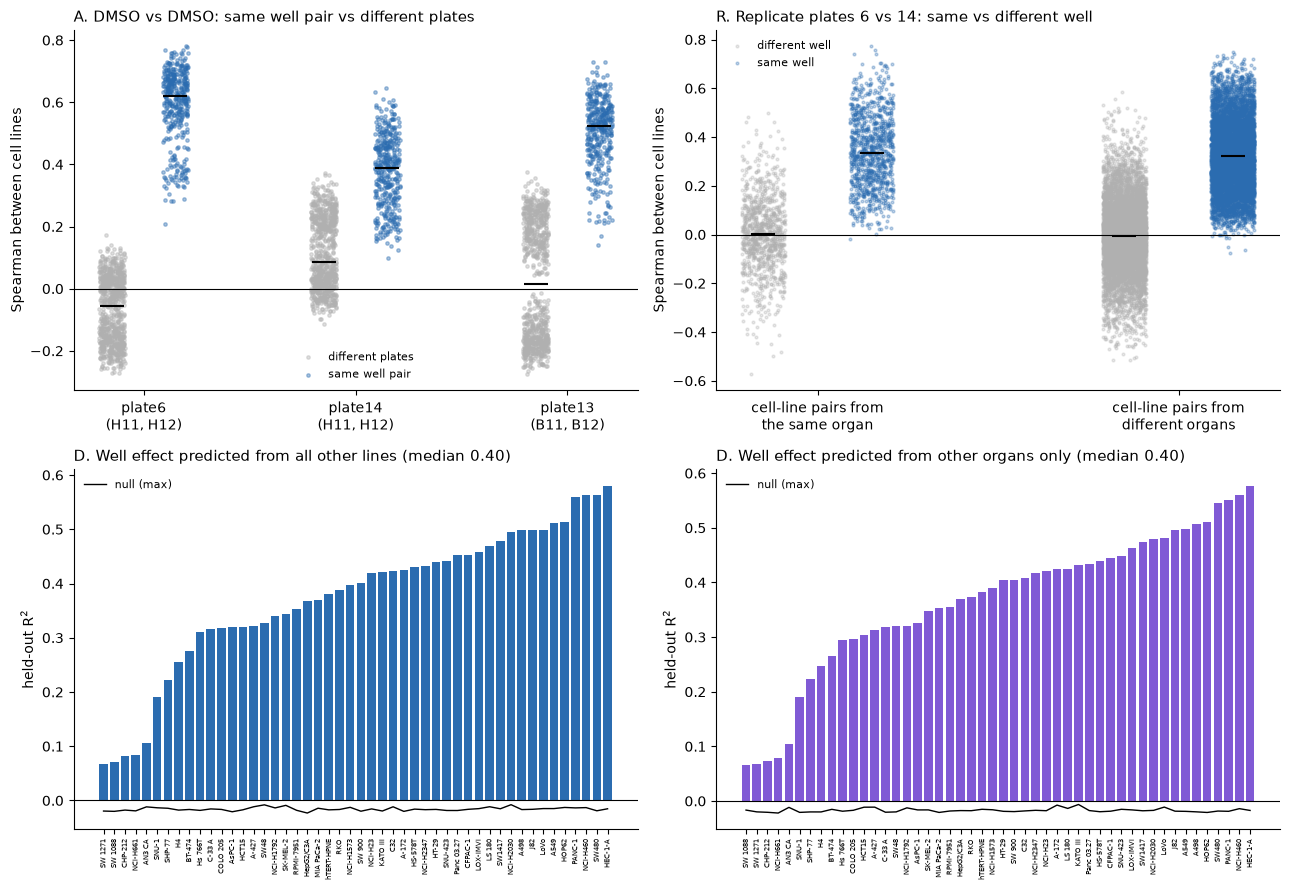

                                                test  same  control  passes
                                       A: DMSO pairs 0.510    0.019    True
                              R: replicate residuals 0.323   -0.006    True
  D: R² above null, all other lines (share of lines) 1.000    0.000    True
D: R² above null, other organs only (share of lines) 1.000    0.000    True


In [10]:
COL = {"same": "#2b6cb0", "ctrl": "#b0b0b0", "alt": "#805ad5"}
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax = ax.ravel()

# A: DMSO pairs per plate
for j, p in enumerate(PLATES):
    for kind, color, off in [("different plates", COL["ctrl"], -0.15), ("same well pair", COL["same"], 0.15)]:
        v = testA[(testA.plate == p) & (testA.kind == kind)].rho
        ax[0].scatter(j + off + rng.uniform(-0.06, 0.06, len(v)), v, s=6, alpha=0.4, color=color,
                      label=kind if j == 0 else None)
        ax[0].scatter(j + off, v.median(), marker="_", s=300, color="k", lw=1.5)
ax[0].set_xticks(range(len(PLATES)))
ax[0].set_xticklabels([f"{p}\n({', '.join(DMSO_WELLS[p][:2])})" for p in PLATES])
ax[0].set_ylabel("Spearman between cell lines")
ax[0].set_title("A. DMSO vs DMSO: same well pair vs different plates", loc="left", fontsize=11)

# R: replicate residuals
for j, (so, lab) in enumerate([(True, "same organ"), (False, "different organ")]):
    for kind, color, off in [("different well", COL["ctrl"], -0.15), ("same well", COL["same"], 0.15)]:
        v = testR[(testR.same_organ == so) & (testR.kind == kind)].rho
        ax[1].scatter(j + off + rng.uniform(-0.06, 0.06, len(v)), v, s=4, alpha=0.3, color=color,
                      label=kind if j == 0 else None)
        ax[1].scatter(j + off, v.median(), marker="_", s=300, color="k", lw=1.5)
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(["cell-line pairs from\nthe same organ", "cell-line pairs from\ndifferent organs"])
ax[1].set_ylabel("Spearman between cell lines")
ax[1].set_title("R. Replicate plates 6 vs 14: same vs different well", loc="left", fontsize=11)

# D: R2 per cell line, sorted
for k, (name, color) in enumerate([("all other lines", COL["same"]), ("other organs only", COL["alt"])]):
    sub = testD[testD.check == name].sort_values("R2")
    ax[2 + k].bar(range(len(sub)), sub.R2, color=color)
    ax[2 + k].plot(range(len(sub)), sub.null_max, color="k", lw=1, label="null (max)")
    ax[2 + k].set_xticks(range(len(sub)))
    ax[2 + k].set_xticklabels(sub.line, rotation=90, fontsize=5)
    ax[2 + k].set_ylabel("held-out R$^2$")
    ax[2 + k].set_title(f"D. Well effect predicted from {name} (median {sub.R2.median():.2f})",
                        loc="left", fontsize=11)
for a_ in ax:
    a_.axhline(0, color="k", lw=0.8)
    a_.spines[["top", "right"]].set_visible(False)
    a_.legend(fontsize=8, frameon=False)
plt.tight_layout()
fig_png = os.path.abspath(os.path.join(OUT_DIR, "aim2_tahoe_shared_well_effect.png"))
fig.savefig(fig_png, dpi=200, bbox_inches="tight")
fig.savefig(fig_png.replace(".png", ".pdf"), bbox_inches="tight")
print("Saved:", fig_png, os.path.exists(fig_png))
plt.show()

a_same = testA[testA.kind == "same well pair"].rho.median()
a_ctrl = testA[testA.kind == "different plates"].rho.median()
r_same = testR[testR.kind == "same well"].rho.median()
r_ctrl = testR[testR.kind == "different well"].rho.median()
dd = testD.assign(gain=testD.R2 - testD.null_max).groupby("check").gain
verdict = pd.DataFrame([
    dict(test="A: DMSO pairs", same=a_same, control=a_ctrl, passes=(a_same - a_ctrl) > 0.05),
    dict(test="R: replicate residuals", same=r_same, control=r_ctrl, passes=(r_same - r_ctrl) > 0.05),
    dict(test="D: R² above null, all other lines (share of lines)", same=float((dd.get_group("all other lines") > 0).mean()),
         control=0.0, passes=bool((dd.get_group("all other lines") > 0).mean() > 0.8)),
    dict(test="D: R² above null, other organs only (share of lines)", same=float((dd.get_group("other organs only") > 0).mean()),
         control=0.0, passes=bool((dd.get_group("other organs only") > 0).mean() > 0.8)),
])
verdict.to_csv(os.path.join(OUT_DIR, "verdict.csv"), index=False)
print(verdict.round(3).to_string(index=False))

## 8. Ambient RNA check
If the shared well effect were ambient RNA, it would lie on the axis "well soup minus the cell line's own profile" (genes the other lines express and this line lacks), its size per well would agree across lines, and it would be larger in lines with fewer UMIs per cell. Decisive test: remove that axis and recompute the same-well correlation.

In [12]:
from scipy.stats import spearmanr
N_AMB_GENES = 5000

def ambient_axis(D, line_cpm, pool_cpm):
    """D: [units, lines, genes] residuals. Returns per-unit ambient coefficient, share of variance, axis."""
    X = np.log2(pool_cpm + 1)[None, :] - np.log2(line_cpm + 1)
    X = X - X.mean(1, keepdims=True)
    U, Lc, _ = D.shape
    beta = np.full((U, Lc), np.nan)
    num, den = np.zeros(Lc), np.zeros(Lc)
    for l in range(Lc):
        x = X[l]; xx = x @ x
        for u in range(U):
            d = D[u, l]
            if np.isnan(d).any():
                continue
            d = d - d.mean()
            b = (d @ x) / xx
            beta[u, l] = b
            num[l] += b * b * xx
            den[l] += d @ d
    return beta, num / np.maximum(den, 1e-12), X

def remove_ambient(D, beta, X):
    return D - np.nan_to_num(beta)[:, :, None] * X[None, :, :]

def beta_consistency(beta, n_pairs=N_LINE_PAIRS):
    out = []
    for _ in range(n_pairs):
        a, b = rng.choice(beta.shape[1], 2, replace=False)
        m = np.where(~np.isnan(beta[:, a]) & ~np.isnan(beta[:, b]))[0]
        if len(m) < 10:
            continue
        out.append((spearmanr(beta[m, a], beta[m, b])[0],
                    spearmanr(beta[m, a], beta[rng.permutation(m), b])[0]))
    return pd.DataFrame(out, columns=["same unit", "shuffled units"])

def sample_pairs(D, n_pairs=N_LINE_PAIRS * 3):
    U, Lc, _ = D.shape
    P = []
    while len(P) < n_pairs:
        u = rng.integers(U); a, b = rng.choice(Lc, 2, replace=False)
        if not (np.isnan(D[u, a, 0]) or np.isnan(D[u, b, 0])):
            P.append((u, a, b))
    return P

def same_unit_corrs(D, pairs):
    return np.array([spearmanr(D[u, a], D[u, b])[0] for u, a, b in pairs])

In [13]:
t0 = time.time()
wmap = pd.read_csv(os.path.join(OUT_DIR, "tahoe_sample_wells_barcode.csv"))
wmap["sample"] = wmap["sample"].astype(str)
pbs = {p: ad.read_h5ad(os.path.join(OUT_DIR, f"pseudobulk_{p}.h5ad")) for p in REPLICATE}

# broad gene set: ambient matters most for genes some lines lack, so not the min-mean set
tot = sum(np.asarray(pbs[p].X.sum(0)).ravel() for p in REPLICATE)
gidx = np.argsort(tot)[::-1][:N_AMB_GENES]
WELLS96 = [r + str(c) for r in "ABCDEFGH" for c in range(1, 13)]
li = {l: i for i, l in enumerate(LINES)}
wi = {w: i for i, w in enumerate(WELLS96)}

def to_tensor(p):
    b = pbs[p]
    o = b.obs.copy()
    o["sample"] = o["sample"].astype(str)
    o["well"] = o["sample"].map(wmap[wmap.plate == p].set_index("sample").well)
    X = b.X[:, gidx]
    X = X.toarray() if sp.issparse(X) else np.asarray(X)
    lib = np.asarray(b.X.sum(1)).ravel()
    T = np.full((96, len(LINES), len(gidx)), np.nan, np.float32)
    raw = np.zeros((len(LINES), len(gidx)))
    cells, libs = np.zeros(len(LINES)), np.zeros(len(LINES))
    for k, (w, l, n) in enumerate(zip(o.well, o.line, o.n_cells)):
        if l not in li or w not in wi:
            continue
        raw[li[l]] += X[k]; cells[li[l]] += n; libs[li[l]] += lib[k]
        if n >= MIN_CELLS:
            T[wi[w], li[l]] = np.log2(X[k] / lib[k] * 1e6 + 1)
    return T, raw, cells, libs

T1, r1, c1, l1 = to_tensor(REPLICATE[0])
T2, r2, c2, l2 = to_tensor(REPLICATE[1])
D = T1 - T2
D = D - np.nanmean(D, axis=0, keepdims=True)        # remove each line's plate-wide offset
raw = r1 + r2
line_cpm = raw / raw.sum(1, keepdims=True) * 1e6
pool_cpm = raw.sum(0) / raw.sum() * 1e6
umi = (l1 + l2) / (c1 + c2)
NAMES, TAG, UNIT = list(LINES), "tahoe", "well"
print(f"D: {D.shape} | {time.time() - t0:.0f}s")

D: (96, 48, 5000) | 3s


done | 2s


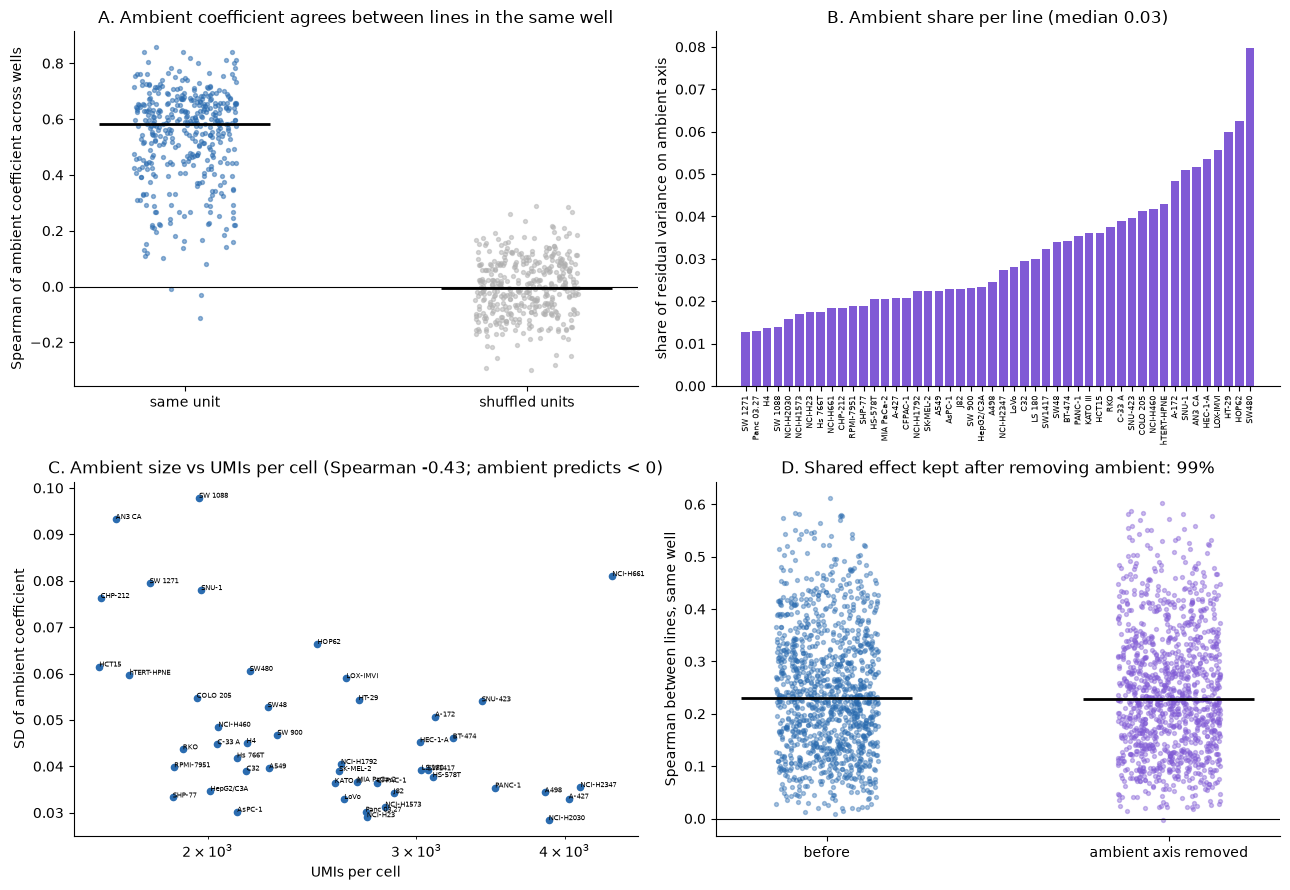

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_tahoe_shared_well_effect/aim2_tahoe_ambient_check.png True
                                                          check                     value
                    ambient share of residual variance (median)                     0.026
   ambient coefficient, same unit vs shuffled (median Spearman)           0.583 vs -0.004
same-unit correlation before -> after removing ambient (median) 0.230 -> 0.228 (99% kept)
             Spearman(SD of ambient coefficient, UMIs per cell)                     -0.43


In [14]:
t0 = time.time()
beta, share, Xamb = ambient_axis(D, line_cpm, pool_cpm)
cons = beta_consistency(beta)
pairs = sample_pairs(D)
before = same_unit_corrs(D, pairs)
after = same_unit_corrs(remove_ambient(D, beta, Xamb), pairs)
spread = np.nanstd(beta, axis=0)
rho_umi = spearmanr(spread, umi)[0]
print(f"done | {time.time() - t0:.0f}s")

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
a = ax[0, 0]
for i, c in enumerate(cons.columns):
    v = cons[c].dropna().values
    a.scatter(i + rng.uniform(-.15, .15, len(v)), v, s=8, alpha=.5, color=["#2b6cb0", "#b0b0b0"][i])
    a.hlines(np.median(v), i - .25, i + .25, color="k", lw=2)
a.set_xticks([0, 1]); a.set_xticklabels(cons.columns); a.axhline(0, color="k", lw=.8)
a.set_ylabel("Spearman of ambient coefficient across " + UNIT + "s")
a.set_title("A. Ambient coefficient agrees between lines in the same " + UNIT)

a = ax[0, 1]
o_ = np.argsort(share)
a.bar(range(len(share)), share[o_], color="#805ad5")
a.set_xticks(range(len(share))); a.set_xticklabels(np.array(NAMES)[o_], rotation=90, fontsize=6)
a.set_ylabel("share of residual variance on ambient axis")
a.set_title(f"B. Ambient share per line (median {np.median(share):.2f})")

a = ax[1, 0]
a.scatter(umi, spread, s=20, color="#2b6cb0")
for x_, y_, n_ in zip(umi, spread, NAMES):
    a.annotate(n_, (x_, y_), fontsize=5)
a.set_xscale("log"); a.set_xlabel("UMIs per cell"); a.set_ylabel("SD of ambient coefficient")
a.set_title(f"C. Ambient size vs UMIs per cell (Spearman {rho_umi:.2f}; ambient predicts < 0)")

a = ax[1, 1]
for i, (lab, v) in enumerate([("before", before), ("ambient axis removed", after)]):
    a.scatter(i + rng.uniform(-.15, .15, len(v)), v, s=8, alpha=.4, color=["#2b6cb0", "#805ad5"][i])
    a.hlines(np.median(v), i - .25, i + .25, color="k", lw=2)
a.set_xticks([0, 1]); a.set_xticklabels(["before", "ambient axis removed"]); a.axhline(0, color="k", lw=.8)
a.set_ylabel("Spearman between lines, same " + UNIT)
a.set_title(f"D. Shared effect kept after removing ambient: {np.median(after) / np.median(before):.0%}")

for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, f"aim2_{TAG}_ambient_check.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

amb = pd.DataFrame({
    "check": ["ambient share of residual variance (median)",
              "ambient coefficient, same unit vs shuffled (median Spearman)",
              "same-unit correlation before -> after removing ambient (median)",
              "Spearman(SD of ambient coefficient, UMIs per cell)"],
    "value": [f"{np.median(share):.3f}",
              f"{cons['same unit'].median():.3f} vs {cons['shuffled units'].median():.3f}",
              f"{np.median(before):.3f} -> {np.median(after):.3f} ({np.median(after) / np.median(before):.0%} kept)",
              f"{rho_umi:.2f}"]})
amb.to_csv(os.path.join(OUT_DIR, f"aim2_{TAG}_ambient_check.csv"), index=False)
print(amb.to_string(index=False))